# Capítulo 5 · Actividad: ¿quién sobrevivió al Titanic?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/01_actividad_titanic_arbol.ipynb)

Entrena un **árbol de decisión** que prediga si un pasajero sobrevivió (`survived`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

In [2]:
from pathlib import Path

import pandas as pd

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_score, learning_curve

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
# Tu código aquí
print ("Filas y columnas del dataset: ", df.shape)
df.info()

Filas y columnas del dataset:  (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [4]:
nulos = df.isna().sum()
nulos[nulos > 0]

age            177
embarked         2
deck           688
embark_town      2
dtype: int64

In [5]:
porcentaje_nulos = nulos[nulos > 0] / len(df) * 100
porcentaje_nulos.sort_values(ascending=False).round(2)

deck           77.22
age            19.87
embarked        0.22
embark_town     0.22
dtype: float64

voy borrar la columna deck para el primer modelo ya que tiene muchos valores nulos (77%) y no creo que haga mucha diferencia a la hora de predecir el resultado, tambien eliminare embarked ya que contiene la misma información que embark_town solo que una tiene el nombre completo del puerto y la otra un código.

In [6]:
df = df.drop(columns=["deck", "embarked"])
df

,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,Second,man,True,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,First,woman,False,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,Third,woman,False,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,First,man,True,Cherbourg,yes,True


De igual manera voy a eliminar la columna class ya que es lo mismo que pclass solo que en texto

In [7]:
df = df.drop(columns=["class"])
df

,survived,pclass,sex,age,sibsp,parch,fare,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,man,True,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,woman,False,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,woman,False,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,man,True,Cherbourg,yes,True


In [8]:
df[["survived", "alive", ]].head(10)

,survived,alive
0,0,no
1,1,yes
2,1,yes
3,1,yes
4,0,no
5,0,no
6,0,no
7,0,no
8,1,yes
9,1,yes


Ahora siguiendo un poco el análisis que hicimos en equipo las clases dejar en el entrenamiento la variable alived o survived le da la respuesta al modelo, sin embargo nos es útil para poder entrenarlo, por lo tanto la voy a dejar como la respuesta (y).

In [9]:
y = df["survived"] #guarda la variable objetivo (respuestas para el modelo)

x = df.drop(columns=["survived", "alive"]) #guarda las variables predictoras sin darle la respuesta al modelo

In [10]:
print("Entradas:", x.columns.tolist())
print("Respuesta:", y.name)

Entradas: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'who', 'adult_male', 'embark_town', 'alone']
Respuesta: survived


In [11]:
y.value_counts(normalize=True) * 100

survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [12]:
df.duplicated().sum()

np.int64(111)

In [13]:
df.loc[df.duplicated(keep=False)].head(10)

,survived,pclass,sex,age,sibsp,parch,fare,who,adult_male,embark_town,alive,alone
4,0,3,male,35.0,0,0,8.0500,man,True,Southampton,no,True
26,0,3,male,NaN,0,0,7.2250,man,True,Cherbourg,no,True
28,1,3,female,NaN,0,0,7.8792,woman,False,Queenstown,yes,True
29,0,3,male,NaN,0,0,7.8958,man,True,Southampton,no,True
32,1,3,female,NaN,0,0,7.7500,woman,False,Queenstown,yes,True
37,0,3,male,21.0,0,0,8.0500,man,True,Southampton,no,True
42,0,3,male,NaN,0,0,7.8958,man,True,Cherbourg,no,True
45,0,3,male,NaN,0,0,8.0500,man,True,Southampton,no,True
46,0,3,male,NaN,1,0,15.5000,man,True,Queenstown,no,False
47,1,3,female,NaN,0,0,7.7500,woman,False,Queenstown,yes,True


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)

In [15]:
print("Entrenamiento:", X_train.shape, y_train.shape)
print("Prueba:", X_test.shape, y_test.shape)

Entrenamiento: (712, 10) (712,)
Prueba: (179, 10) (179,)


De aquí en adelante ya voy a revisar con los datos de entrenamiento para el primer modelo, de momento no hice nada de clasidicar por edades y así como lo hicimos en la actividad pasada.

In [16]:
X_train.isna().sum()

pclass           0
sex              0
age            137
sibsp            0
parch            0
fare             0
who              0
adult_male       0
embark_town      2
alone            0
dtype: int64

In [17]:
X_train["age"].describe()

count    575.000000
mean      29.807687
std       14.485211
min        0.420000
25%       21.000000
50%       28.500000
75%       39.000000
max       80.000000
Name: age, dtype: float64

In [18]:
imputador_edad = SimpleImputer(strategy="mean")

Voy a usar a media para rellenar las edades que faltan para este primer modelo, en lo que meto la validación cruzada y ya viendo su desempeño veo si uso la mediana xd

como tambien hay nulos en embarked_town pero ahí no hay mediana voy a usar el que más se repita, la moda

In [19]:
X_train["embark_town"].value_counts(dropna=False)

embark_town
Southampton    516
Cherbourg      139
Queenstown      55
NaN              2
Name: count, dtype: int64

In [20]:
imputador_puerto = SimpleImputer(strategy="most_frequent")

In [21]:
imputador_puerto.fit(X_train[["embark_town"]])
imputador_puerto.statistics_

array(['Southampton'], dtype=object)

para entender como jala el OneHotEncoder pq se me va

In [22]:
codificador = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [23]:
codificador.fit(X_train[["sex"]])
codificador.get_feature_names_out()

array(['sex_female', 'sex_male'], dtype=object)

In [24]:
codificador.transform(X_train[["sex"]].head())

array([[0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.]])

In [25]:
X_train[["sex"]].head()

,sex
692,male
481,male
527,male
855,female
801,female


listo, ya puedo pasar al pipeline que hace lo del OneHotEncoder y clasificar sex, who y embarktown con un número

In [26]:
categoricas = ["sex", "who", "embark_town"]

preparacion_categorica = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )),
])

In [27]:
categoricas_train = preparacion_categorica.fit_transform(
    X_train[categoricas]
)

In [28]:
print(categoricas_train.shape)
print(preparacion_categorica.get_feature_names_out())

(712, 8)
['sex_female' 'sex_male' 'who_child' 'who_man' 'who_woman'
 'embark_town_Cherbourg' 'embark_town_Queenstown'
 'embark_town_Southampton']


In [29]:
numericas = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Variables numéricas:", numericas)

Variables numéricas: ['pclass', 'age', 'sibsp', 'parch', 'fare', 'adult_male', 'alone']


In [30]:
preparacion = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="mean"), numericas),
    ("categoricas", preparacion_categorica, categoricas),
])

In [31]:
X_train_preparado = preparacion.fit_transform(X_train)
print(X_train_preparado.shape)

(712, 15)


ahora si el primer modelo 

In [32]:
modelo_base = Pipeline([
    ("preparacion", preparacion),
    ("arbol", DecisionTreeClassifier(random_state=42)),
])

In [33]:
modelo_base.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('arbol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['pclass','sex','age',...,'adult_male','embark_town','alone']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, a

In [34]:
acierto_train = modelo_base.score(X_train, y_train)
print("Porcentaje de aciertos en entrenamiento:", acierto_train * 100)

Porcentaje de aciertos en entrenamiento: 98.31460674157303


In [35]:
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

In [36]:
scores_base = cross_val_score(
    modelo_base, X_train, y_train,
    cv=cv, scoring="accuracy"
)

In [37]:
print("Aciertos por partición (%):", (scores_base * 100).round(2))
print("Media de aciertos (%):", scores_base.mean() * 100)

Aciertos por partición (%): [76.22 75.52 78.17 78.87 79.58]
Media de aciertos (%): 77.67359401162219


In [38]:
rejilla = {"arbol__max_depth": [2, 3, 4, 5, 6, 8, None]}

In [39]:
busqueda = GridSearchCV(
    modelo_base, rejilla, cv=cv, scoring="accuracy"
)
busqueda.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'arbol__max_depth': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of in

In [40]:
print("Mejor configuración:", busqueda.best_params_)
print("Media de aciertos en validación (%):", busqueda.best_score_ * 100)

Mejor configuración: {'arbol__max_depth': 5}
Media de aciertos en validación (%): 80.89727174234216


In [41]:
modelo_opt = busqueda.best_estimator_

In [42]:
acierto_train_opt = modelo_opt.score(X_train, y_train)

print("Entrenamiento (%):", acierto_train_opt * 100)
print("Validación cruzada (%):", busqueda.best_score_ * 100)

Entrenamiento (%): 87.07865168539325
Validación cruzada (%): 80.89727174234216


validación con el conjunto de prueba

In [43]:
acierto_test = modelo_opt.score(X_test, y_test)
print("Aciertos en prueba (%):", acierto_test * 100)

Aciertos en prueba (%): 80.44692737430168


In [44]:
pred_test = modelo_opt.predict(X_test)

In [45]:
matriz = confusion_matrix(y_test, pred_test, labels=[0, 1])

In [46]:
pd.DataFrame(
    matriz,
    index=["Real: falleció", "Real: sobrevivió"],
    columns=["Predijo: falleció", "Predijo: sobrevivió"]
)

,Predijo: falleció,Predijo: sobrevivió
Real: falleció,99,11
Real: sobrevivió,24,45


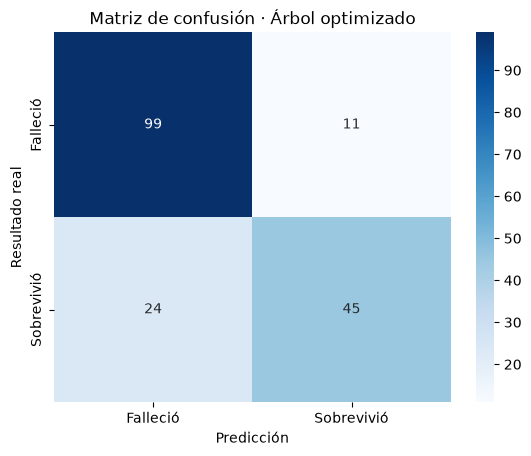

In [47]:
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Falleció", "Sobrevivió"],
    yticklabels=["Falleció", "Sobrevivió"]
)
plt.xlabel("Predicción")
plt.ylabel("Resultado real")
plt.title("Matriz de confusión · Árbol optimizado")
plt.show()

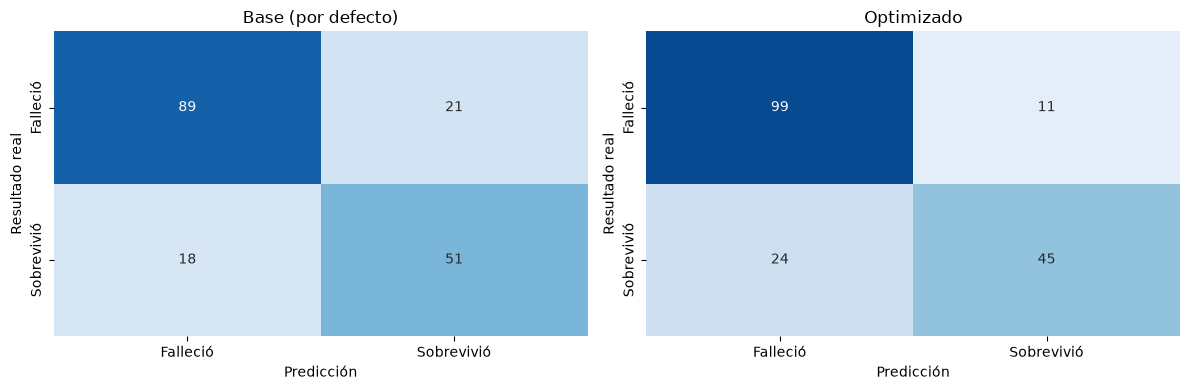

In [48]:
modelos = {
    "Base (por defecto)": modelo_base,
    "Optimizado": modelo_opt,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for (nombre, modelo), ax in zip(modelos.items(), axes):
    predicciones = modelo.predict(X_test)
    matriz_actual = confusion_matrix(y_test, predicciones, labels=[0, 1])

    sns.heatmap(
        matriz_actual, annot=True, fmt="d", cmap="Blues",
        vmin=0, vmax=y_test.value_counts().max(), cbar=False,
        xticklabels=["Falleció", "Sobrevivió"],
        yticklabels=["Falleció", "Sobrevivió"],
        ax=ax,
    )
    ax.set(title=nombre, xlabel="Predicción", ylabel="Resultado real")

plt.tight_layout()
plt.show()

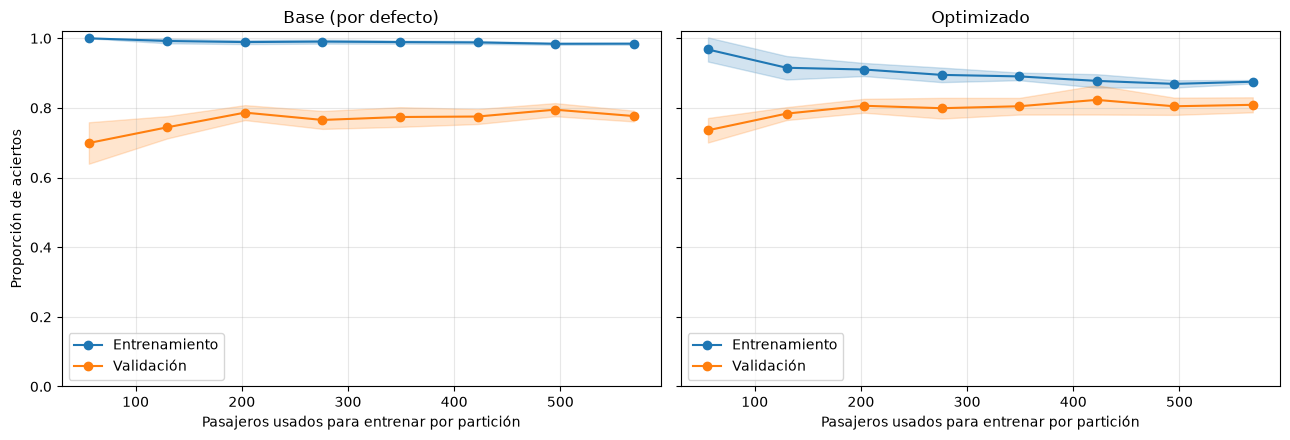

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for (nombre, modelo), ax in zip(modelos.items(), axes):
    tamanos, scores_train, scores_val = learning_curve(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        train_sizes=np.linspace(0.1, 1.0, 8),
        shuffle=True,
        random_state=42,
    )

    for puntuaciones, etiqueta, color in [
        (scores_train, "Entrenamiento", "tab:blue"),
        (scores_val, "Validación", "tab:orange"),
    ]:
        media = puntuaciones.mean(axis=1)
        desviacion = puntuaciones.std(axis=1)

        ax.plot(tamanos, media, "o-", label=etiqueta, color=color)
        ax.fill_between(
            tamanos, media - desviacion, media + desviacion,
            color=color, alpha=0.2,
        )

    ax.set(
        title=nombre,
        xlabel="Pasajeros usados para entrenar por partición",
        ylim=(0, 1.02),
    )
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Proporción de aciertos")
plt.tight_layout()
plt.show()

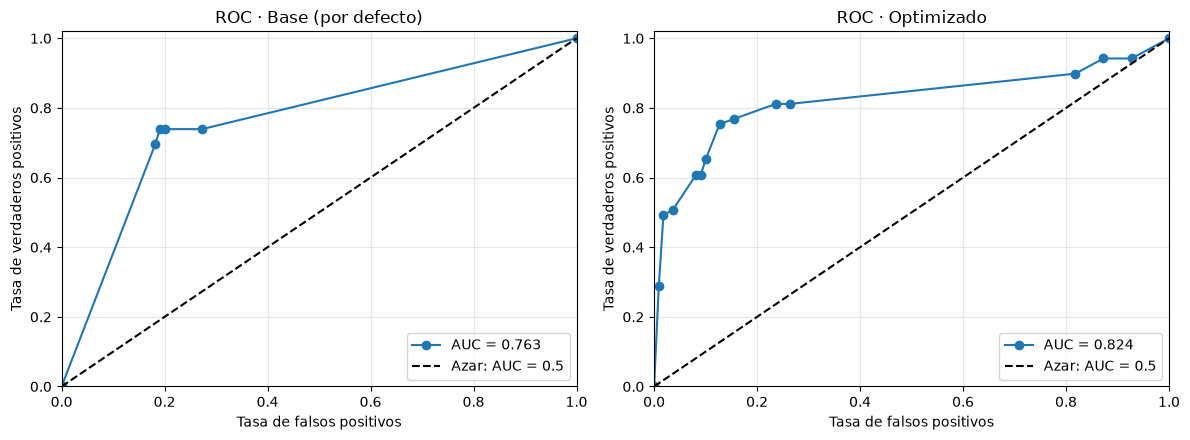

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for (nombre, modelo), ax in zip(modelos.items(), axes):
    probabilidades = modelo.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probabilidades, pos_label=1)
    auc = roc_auc_score(y_test, probabilidades)

    ax.plot(fpr, tpr, marker="o", label=f"AUC = {auc:.3f}")
    ax.plot([0, 1], [0, 1], "k--", label="Azar: AUC = 0.5")

    ax.set(
        title=f"ROC · {nombre}",
        xlabel="Tasa de falsos positivos",
        ylabel="Tasa de verdaderos positivos",
        xlim=(0, 1),
        ylim=(0, 1.02),
    )
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
scores_opt = cross_val_score(
    modelo_opt, X_train, y_train,
    cv=cv, scoring="accuracy",
)

In [52]:
def evaluar_para_reporte(modelo, resultados_cv):
    predicciones = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)[:, 1]
    arbol = modelo.named_steps["arbol"]

    return {
        "Accuracy train": modelo.score(X_train, y_train),
        "Accuracy CV (media)": resultados_cv.mean(),
        "Accuracy CV (desv.)": resultados_cv.std(),
        "Accuracy test": modelo.score(X_test, y_test),
        "F1 macro test": f1_score(
            y_test, predicciones, average="macro"
        ),
        "AUC test": roc_auc_score(y_test, probabilidades),
        "Profundidad": arbol.get_depth(),
        "Hojas": arbol.get_n_leaves(),
    }


reporte = pd.DataFrame({
    "Base (por defecto)": evaluar_para_reporte(modelo_base, scores_base),
    "Optimizado": evaluar_para_reporte(modelo_opt, scores_opt),
}).T

display(reporte.round(3))

,Accuracy train,Accuracy CV (media),Accuracy CV (desv.),Accuracy test,F1 macro test,AUC test,Profundidad,Hojas
Base (por defecto),0.983,0.777,0.016,0.782,0.772,0.763,22.0,160.0
Optimizado,0.871,0.809,0.022,0.804,0.785,0.824,5.0,24.0


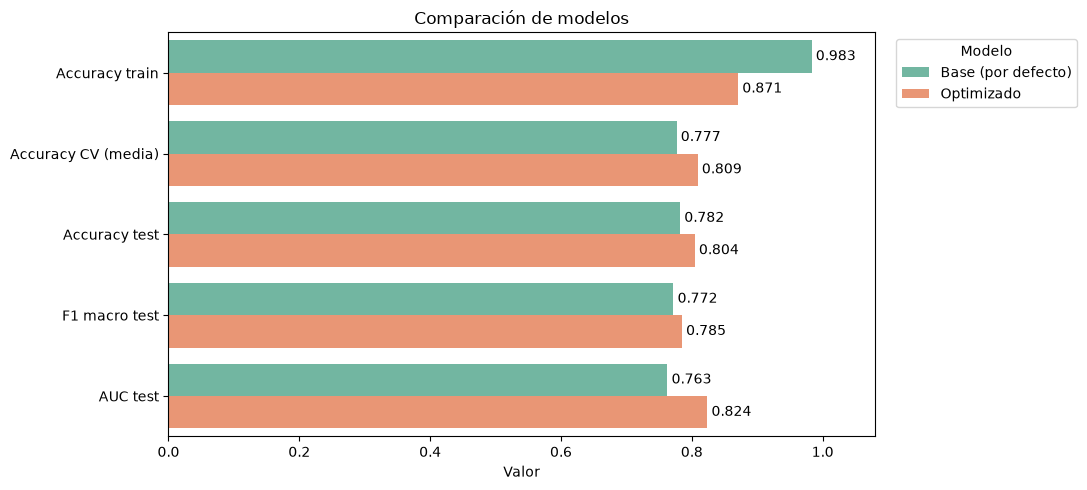

In [53]:
metricas = [
    "Accuracy train",
    "Accuracy CV (media)",
    "Accuracy test",
    "F1 macro test",
    "AUC test",
]

reporte_largo = (
    reporte[metricas]
    .reset_index(names="modelo")
    .melt(id_vars="modelo", var_name="metrica", value_name="valor")
)

plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=reporte_largo,
    x="valor",
    y="metrica",
    hue="modelo",
    palette="Set2",
    errorbar=None,
)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", padding=3)

ax.set(
    title="Comparación de modelos",
    xlabel="Valor",
    ylabel="",
    xlim=(0, 1.08),
)
ax.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [54]:
rejilla = {"arbol__max_depth": [2, 3, 4, 5, 6, 8, None]}

In [55]:
resultados = pd.DataFrame(busqueda.cv_results_)

resultados[[
    "param_arbol__max_depth",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]].sort_values("rank_test_score")

,param_arbol__max_depth,mean_test_score,std_test_score,rank_test_score
3,5,0.808973,0.021544,1
2,4,0.804836,0.017838,2
0,2,0.803339,0.018626,3
1,3,0.802019,0.018472,4
4,6,0.801930,0.025104,5
5,8,0.794898,0.035511,6
6,None,0.776736,0.015511,7
